In [79]:
from langchain_mistralai import MistralAIEmbeddings
from langgraph.store.memory import InMemoryStore 
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_groq import ChatGroq

from dotenv import load_dotenv
load_dotenv()

True

In [80]:
embedding = MistralAIEmbeddings(model="mistral-embed")
store = InMemoryStore(index={
    "embed": embedding,
    "dimension": 1024
})

In [81]:
namespace = ('user','u1')

In [82]:
store.put(namespace, "1", {"data": "I am a React and Node.js developer"})
store.put(namespace, "2", {"data": "I am learning system design"})
store.put(namespace, "3", {"data": "I am learning LangGraph"})
store.put(namespace, "4", {"data": "I prefer short and concise explanations"})
store.put(namespace, "5", {"data": "I am building a LangGraph chatbot"})
store.put(namespace, "6", {"data": "I want to learn long-term memory"})
store.put(namespace, "7", {"data": "I use Manjaro Linux"})
store.put(namespace, "8", {"data": "I am preparing for senior developer interviews"})

In [83]:
class MemoryState:
    query: str
    user_memory: Annotated[str, "Memory"] = ""

class ChatState:
    query: str
    response: Annotated[str, "Response"] = ""

In [84]:
llm = ChatGroq(model='openai/gpt-oss-120b',temperature=0.1)

In [85]:
def seach_in_memory(state,config,store):
    user_id = config['configurable']['user_id']
    namespace = ('user',user_id)
    query = state['query']

    print(namespace,query,store)

    items = store.search(namespace,query=query,limit=2)

    memory = "\n".join(f"- {item.value.get('data','')}" for item in items)

    print('Memory',memory)

    return {
        "user_memory": memory
    }

In [86]:
sub_graph = StateGraph(MemoryState)

sub_graph.add_node('search_in_memory', seach_in_memory)

sub_graph.add_edge(START, 'search_in_memory')
sub_graph.add_edge('search_in_memory', END)

sub_graph_workflow = sub_graph.compile()

In [87]:
def chat_node(state,config):
    result = sub_graph_workflow.invoke({'query': state['query']},config)

    query = f"""
Relevant memory:
{result['user_memory']}

Query:
{state['query']}
"""

    print('Query',query)
    response = llm.invoke(query)

    return {
        "response": response.content
    }

In [88]:
graph = StateGraph(ChatState)

graph.add_node('chat_node', chat_node)

graph.add_edge(START,'chat_node')
graph.add_edge('chat_node',END)

workflow = graph.compile(store=store)

In [89]:
workflow.invoke({'query': 'What technologies do I work with?'}, config={'configurable': {'user_id': 'u1'}})

('user', 'u1') What technologies do I work with? <langgraph.store.memory.InMemoryStore object at 0x7f2f434d8640>
Memory - I am a React and Node.js developer
- I am learning system design
Query 
Relevant memory:
- I am a React and Node.js developer
- I am learning system design

Query:
What technologies do I work with?



{'query': 'What technologies do I work with?',
 'response': 'Based on what you’ve shared, the primary technologies you work with are:\n\n- **React** (front‑end UI library)  \n- **Node.js** (server‑side JavaScript runtime)  \n\nThese typically involve the surrounding ecosystem as well, such as:\n\n- JavaScript/TypeScript  \n- npm/Yarn for package management  \n- Express (or similar) for building APIs with Node.js  \n- HTML & CSS (or CSS‑in‑JS solutions) for styling React components  \n\nAnd you’re currently expanding your skill set into **system design** concepts.'}

In [90]:
class State(TypedDict):
    query: str
    analysis: str
    response: str

In [91]:
def analysis_node(state: State):
    prompt = f"""
Analyze the user's question.

Question:
{state["query"]}

Give 2-3 important points.
"""

    response = llm.invoke(prompt)

    return {
        "analysis": response.content
    }

In [92]:
analysis_graph = StateGraph(State)

analysis_graph.add_node("analyze", analysis_node)

analysis_graph.add_edge(START, "analyze")
analysis_graph.add_edge("analyze", END)

analysis_subgraph = analysis_graph.compile()

In [93]:
def chat_node(state: State):

    prompt = f"""
Answer the user's question using the analysis below.

Question:
{state["query"]}

Analysis:
{state["analysis"]}

Give a concise answer.
"""

    response = llm.invoke(prompt)

    return {
        "response": response.content
    }

In [94]:
graph = StateGraph(State)

graph.add_node("analysis", analysis_subgraph)
graph.add_node("chat", chat_node)

graph.add_edge(START, "analysis")
graph.add_edge("analysis", "chat")
graph.add_edge("chat", END)

workflow = graph.compile()

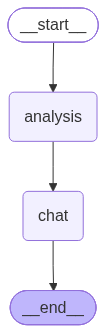

In [96]:
from IPython.display import display, Image
display(Image(workflow.get_graph().draw_mermaid_png()))

In [102]:
result = workflow.invoke({
    "query": "Should I use PostgreSQL or MongoDB for an e-commerce application?",
    "analysis": "",
    "response": ""
})

In [103]:
print(result['query'])
print(result['analysis'])

Should I use PostgreSQL or MongoDB for an e-commerce application?
**PostgreSQL (relational)**  
1. **Strong ACID guarantees & complex transactions** – E‑commerce systems need reliable order processing, inventory updates, and payment handling. PostgreSQL’s proven ACID compliance and support for multi‑row, multi‑table transactions make it easier to keep data consistent under high concurrency.  
2. **Rich relational modeling & referential integrity** – Products, categories, customers, orders, and shipments naturally fit a normalized schema with foreign‑key constraints, joins, and cascading rules. This reduces data duplication and helps enforce business rules directly in the database.  

**MongoDB (document‑oriented)**  
1. **Flexible schema & rapid feature iteration** – If you expect frequent changes to product attributes (e.g., dynamic specs, promotions, user‑generated metadata), MongoDB’s schemaless documents let you add fields without migrations, speeding up development.  
2. **Built‑i

In [104]:
print(result['response'])

**Use PostgreSQL for the core e‑commerce data** – orders, payments, inventory, customers, and shipments. Its strong ACID guarantees, multi‑table transactions, and referential integrity keep financial and stock information consistent under high concurrency.

**Use MongoDB only for the parts that need schema flexibility or massive read‑heavy scaling** – e.g., a product catalog with ever‑changing attributes, user‑generated metadata, or session/cache data. Its document model lets you add fields without migrations, and sharding/replica sets handle traffic spikes.

**Bottom line:**  
- **PostgreSQL** → primary store for anything that must be transactionally correct and relational.  
- **MongoDB** → supplemental store for flexible, high‑throughput, non‑critical data.

Many teams adopt a **hybrid approach**: PostgreSQL for orders/payments, MongoDB for the catalog or analytics layer. Choose the hybrid if you need both strong consistency and schema agility; otherwise, stick with PostgreSQL for a